In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
data = {
    'StudyHours': [2, 4, 6, 8, 10],
    'Attendance': [60, 70, 80, 90, 100],
    'PreviousMarks': [55, 65, 75, 85, 95],
    'AssignmentMarks': [50, 60, 70, 80, 90]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

Original Dataset:
   StudyHours  Attendance  PreviousMarks  AssignmentMarks
0           2          60             55               50
1           4          70             65               60
2           6          80             75               70
3           8          90             85               80
4          10         100             95               90


In [3]:
# Create MinMaxScaler
scaler = MinMaxScaler()

# Apply normalization
normalized_data = scaler.fit_transform(df)

# Convert into DataFrame
normalized_df = pd.DataFrame(
    normalized_data,
    columns=df.columns
)

print("Normalized Dataset:")
print(normalized_df)

Normalized Dataset:
   StudyHours  Attendance  PreviousMarks  AssignmentMarks
0        0.00        0.00           0.00             0.00
1        0.25        0.25           0.25             0.25
2        0.50        0.50           0.50             0.50
3        0.75        0.75           0.75             0.75
4        1.00        1.00           1.00             1.00


In [4]:
print("Original Data:")
display(df)

print("Normalized Data:")
display(normalized_df)

Original Data:


,StudyHours,Attendance,PreviousMarks,AssignmentMarks
0,2,60,55,50
1,4,70,65,60
2,6,80,75,70
3,8,90,85,80
4,10,100,95,90


Normalized Data:


,StudyHours,Attendance,PreviousMarks,AssignmentMarks
0,0.00,0.00,0.00,0.00
1,0.25,0.25,0.25,0.25
2,0.50,0.50,0.50,0.50
3,0.75,0.75,0.75,0.75
4,1.00,1.00,1.00,1.00


In [5]:
# Create StandardScaler
std_scaler = StandardScaler()

# Apply standardization
standardized_data = std_scaler.fit_transform(df)

# Convert into DataFrame
standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("Standardized Dataset:")
display(standardized_df)

Standardized Dataset:


,StudyHours,Attendance,PreviousMarks,AssignmentMarks
0,-1.414214,-1.414214,-1.414214,-1.414214
1,-0.707107,-0.707107,-0.707107,-0.707107
2,0.000000,0.000000,0.000000,0.000000
3,0.707107,0.707107,0.707107,0.707107
4,1.414214,1.414214,1.414214,1.414214


In [6]:
# Calculate mean
mean = df.mean()

# Calculate standard deviation
std = df.std(ddof=0)

print("Mean:")
print(mean)

print("\nStandard Deviation:")
print(std)

Mean:
StudyHours          6.0
Attendance         80.0
PreviousMarks      75.0
AssignmentMarks    70.0
dtype: float64

Standard Deviation:
StudyHours          2.828427
Attendance         14.142136
PreviousMarks      14.142136
AssignmentMarks    14.142136
dtype: float64


In [7]:
z_scores = (df - mean) / std

print("Z-score Table:")
display(z_scores)

Z-score Table:


,StudyHours,Attendance,PreviousMarks,AssignmentMarks
0,-1.414214,-1.414214,-1.414214,-1.414214
1,-0.707107,-0.707107,-0.707107,-0.707107
2,0.000000,0.000000,0.000000,0.000000
3,0.707107,0.707107,0.707107,0.707107
4,1.414214,1.414214,1.414214,1.414214


In [8]:
# Create PCA dataset
pca_data = pd.DataFrame({
    'StudyHours': [1, 2, 3, 4],
    'PreviousMarks': [2, 3, 4, 5]
})

print("Original PCA Dataset:")
display(pca_data)

Original PCA Dataset:


,StudyHours,PreviousMarks
0,1,2
1,2,3
2,3,4
3,4,5


In [9]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(pca_data)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=pca_data.columns
)

print("Standardized PCA Data:")
display(scaled_df)

Standardized PCA Data:


,StudyHours,PreviousMarks
0,-1.341641,-1.341641
1,-0.447214,-0.447214
2,0.447214,0.447214
3,1.341641,1.341641


In [10]:
cov_matrix = np.cov(scaled_data.T)

print("Covariance Matrix:")
print(cov_matrix)

Covariance Matrix:
[[1.33333333 1.33333333]
 [1.33333333 1.33333333]]


In [11]:
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

Eigenvalues:
[2.66666667 0.        ]

Eigenvectors:
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


In [12]:
# Sort eigenvalues
indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

print("Sorted Eigenvalues:")
print(eigenvalues)

print("\nSorted Eigenvectors:")
print(eigenvectors)

Sorted Eigenvalues:
[2.66666667 0.        ]

Sorted Eigenvectors:
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


In [13]:
total_variance = sum(eigenvalues)

explained_variance = (
    eigenvalues / total_variance
) * 100

print("Explained Variance (%):")
print(explained_variance)

Explained Variance (%):
[100.   0.]


In [14]:
pca = PCA(n_components=1)

principal_components = pca.fit_transform(scaled_data)

print("Principal Components:")
print(principal_components)

Principal Components:
[[ 1.8973666 ]
 [ 0.63245553]
 [-0.63245553]
 [-1.8973666 ]]


In [15]:
principal_df = pd.DataFrame(
    principal_components,
    columns=['PC1']
)

print("Reduced Dataset:")
display(principal_df)

Reduced Dataset:


,PC1
0,1.897367
1,0.632456
2,-0.632456
3,-1.897367


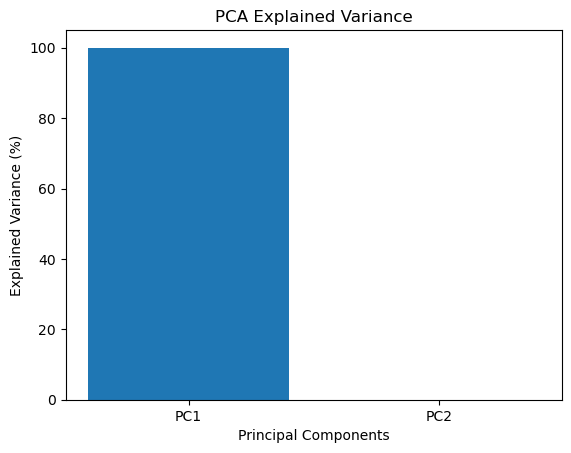

In [16]:
plt.bar(
    ['PC1', 'PC2'],
    explained_variance
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance")

plt.show()

In [21]:
print("Original Dataset:")
display(pca_data)

print("Standardized Dataset:")
display(scaled_df)

print("Covariance Matrix:")
print(cov_matrix)

print("Eigenvalues:")
print(eigenvalues)

print("Eigenvectors:")
print(eigenvectors)

print("Explained Variance:")
print(explained_variance)

print("Final Reduced Dataset:")
display(principal_df)

Original Dataset:


,StudyHours,PreviousMarks
0,1,2
1,2,3
2,3,4
3,4,5


Standardized Dataset:


,StudyHours,PreviousMarks
0,-1.341641,-1.341641
1,-0.447214,-0.447214
2,0.447214,0.447214
3,1.341641,1.341641


Covariance Matrix:
[[1.33333333 1.33333333]
 [1.33333333 1.33333333]]
Eigenvalues:
[2.66666667 0.        ]
Eigenvectors:
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]
Explained Variance:
[100.   0.]
Final Reduced Dataset:


,PC1
0,1.897367
1,0.632456
2,-0.632456
3,-1.897367


Original Dataset:


,StudyHours,Attendance,PreviousMarks,AssignmentMarks
0,2,60,55,50
1,4,70,65,60
2,6,80,75,70
3,8,90,85,80
4,10,100,95,90


Normalized Dataset:


,StudyHours,Attendance,PreviousMarks,AssignmentMarks
0,0.00,0.00,0.00,0.00
1,0.25,0.25,0.25,0.25
2,0.50,0.50,0.50,0.50
3,0.75,0.75,0.75,0.75
4,1.00,1.00,1.00,1.00


Standardized Dataset:


,StudyHours,Attendance,PreviousMarks,AssignmentMarks
0,-1.414214,-1.414214,-1.414214,-1.414214
1,-0.707107,-0.707107,-0.707107,-0.707107
2,0.000000,0.000000,0.000000,0.000000
3,0.707107,0.707107,0.707107,0.707107
4,1.414214,1.414214,1.414214,1.414214


... (4 outputs left out)

Standardized PCA Data:


,StudyHours,PreviousMarks
0,-1.414214,-1.414214
1,-0.707107,-0.707107
2,0.000000,0.000000
3,0.707107,0.707107
4,1.414214,1.414214


Covariance Matrix:
[[1.25 1.25]
 [1.25 1.25]]

Eigenvalues:
[0.  2.5]

Eigenvectors:
[[-0.70710678  0.70710678]
 [ 0.70710678  0.70710678]]

Sorted Eigenvalues:
[2.5 0. ]

Sorted Eigenvectors:
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]

Explained Variance (%):
[100.   0.]

Principal Components:
[[ 2.]
 [ 1.]
 [-0.]
 [-1.]
 [-2.]]

Reduced Dataset:


,PC1
0,2.0
1,1.0
2,-0.0
3,-1.0
4,-2.0


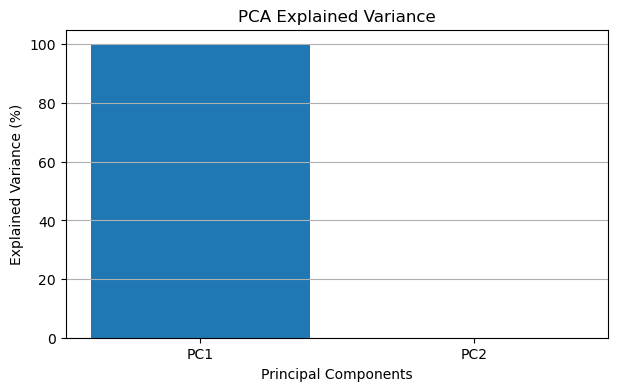

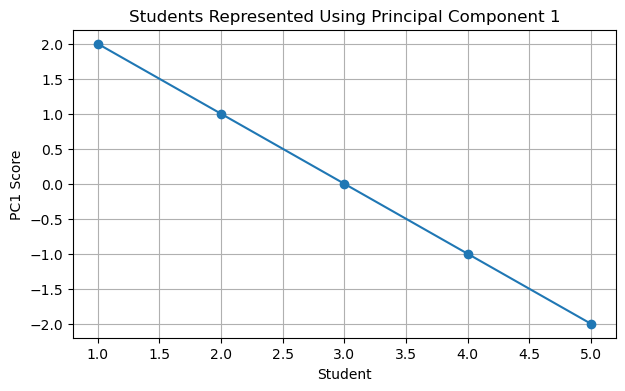


========== FINAL PCA RESULTS ==========

Original PCA Dataset:


,StudyHours,PreviousMarks
0,2,55
1,4,65
2,6,75
3,8,85
4,10,95


Standardized PCA Dataset:


,StudyHours,PreviousMarks
0,-1.414214,-1.414214
1,-0.707107,-0.707107
2,0.000000,0.000000
3,0.707107,0.707107
4,1.414214,1.414214


Covariance Matrix:
[[1.25 1.25]
 [1.25 1.25]]

Eigenvalues:
[2.5 0. ]

Eigenvectors:
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]

Explained Variance:
[100.   0.]

Final Reduced Dataset:


,PC1
0,2.0
1,1.0
2,-0.0
3,-1.0
4,-2.0


In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# 1. Create Original Dataset
data = {
    'StudyHours': [2, 4, 6, 8, 10],
    'Attendance': [60, 70, 80, 90, 100],
    'PreviousMarks': [55, 65, 75, 85, 95],
    'AssignmentMarks': [50, 60, 70, 80, 90]
}

df = pd.DataFrame(data)

print("Original Dataset:")
display(df)


# 2. Normalization using MinMaxScaler
scaler = MinMaxScaler()

normalized_data = scaler.fit_transform(df)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=df.columns
)

print("Normalized Dataset:")
display(normalized_df)


# 3. Standardization using StandardScaler
std_scaler = StandardScaler()

standardized_data = std_scaler.fit_transform(df)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("Standardized Dataset:")
display(standardized_df)


# 4. Calculate Mean and Standard Deviation
mean = df.mean()
std = df.std(ddof=0)

print("Mean:")
print(mean)

print("\nStandard Deviation:")
print(std)


# 5. Calculate Z-Scores
z_scores = (df - mean) / std

print("\nZ-score Table:")
display(z_scores)


# 6. Create PCA Dataset
pca_data = pd.DataFrame({
    'StudyHours': [2, 4, 6, 8, 10],
    'PreviousMarks': [55, 65, 75, 85, 95]
})

print("Original PCA Dataset:")
display(pca_data)


# 7. Standardize PCA Dataset
scaler = StandardScaler()

scaled_data = scaler.fit_transform(pca_data)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=pca_data.columns
)

print("Standardized PCA Data:")
display(scaled_df)


# 8. Calculate Covariance Matrix
cov_matrix = np.cov(scaled_data.T)

print("Covariance Matrix:")
print(cov_matrix)


# 9. Calculate Eigenvalues and Eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

print("\nEigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)


# 10. Sort Eigenvalues and Eigenvectors
indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

print("\nSorted Eigenvalues:")
print(eigenvalues)

print("\nSorted Eigenvectors:")
print(eigenvectors)


# 11. Calculate Explained Variance
total_variance = sum(eigenvalues)

explained_variance = (
    eigenvalues / total_variance
) * 100

print("\nExplained Variance (%):")
print(explained_variance)


# 12. Apply PCA
pca = PCA(n_components=1)

principal_components = pca.fit_transform(scaled_data)

print("\nPrincipal Components:")
print(principal_components)


# 13. Create Reduced Dataset
principal_df = pd.DataFrame(
    principal_components,
    columns=['PC1']
)

print("\nReduced Dataset:")
display(principal_df)


# 14. Plot Explained Variance
plt.figure(figsize=(7, 4))

plt.bar(
    ['PC1', 'PC2'],
    explained_variance
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance")
plt.grid(axis='y')

plt.show()


# 15. Plot Students Represented Using PC1
plt.figure(figsize=(7, 4))

plt.plot(
    pca_data.index + 1,
    principal_df["PC1"],
    marker="o"
)

plt.xlabel("Student")
plt.ylabel("PC1 Score")
plt.title("Students Represented Using Principal Component 1")

plt.grid(True)
plt.show()


# 16. Display Final Results
print("\n========== FINAL PCA RESULTS ==========")

print("\nOriginal PCA Dataset:")
display(pca_data)

print("Standardized PCA Dataset:")
display(scaled_df)

print("Covariance Matrix:")
print(cov_matrix)

print("\nEigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

print("\nExplained Variance:")
print(explained_variance)

print("\nFinal Reduced Dataset:")
display(principal_df)
